# Pillbox cavity — conductivity sweep: WAKIS SIBC eigenmodes vs CST / IDDEFIX

**Goal:** Compare the selected cavity resonance across wall conductivities using **WAKIS PEC eigenmode + first-order SIBC projection** and **CST wakefield impedances fitted with IDDEFIX**. No direct WAKIS FD frequency sweep.

Outputs: $f_r$, $Q$, shunt impedance $R_s$ and $R_s/Q$ versus conductivity, with optional individual CST fit diagnostics.

**Model limitations:** The perturbation retains PEC eigenvectors and neglects SIBC-induced cross-mode coupling. CST wakefield spectra may have finite-wake broadening. The `R_s` here is the *beam shunt impedance*, **not** the surface resistance $R_\mathrm{surf}$. Compare shunt-impedance conventions carefully (possible factor of 2).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
from scipy.constants import pi
from scipy.sparse import diags
import re
import pandas as pd
import iddefix
from scipy.optimize import least_squares
from wakis import GridFIT3D, WakeSolver
from wakis.solverFIT3D_FD import SolverFIT3D_FD


BETA = 1.0
Q = 1.0e-9
SIGMAZ = 0.1
WAKELENGTH = 100.0

XSOURCE = 0.0
YSOURCE = 0.0
XTEST = 0.0
YTEST = 0.0

# Keep the integration interval identical between TD and the current FD
# implementation. If boundary contamination becomes relevant later, introduce
# the same integration mask explicitly in both methods.
SKIP_CELLS = 0

## 1. Locate the STL files and inspect bounds

Run this notebook from `notebooks/` or another WAKIS repository directory. If your files are elsewhere, update `stl_dir` manually. The vacuum mesh is used for bounds and visualization; the **lossy-metal shell** is the only STL assigned to the solver.

In [2]:
root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
search_dirs = [p / "tests" / "stl" for p in root_candidates]
search_dirs += [p / "notebooks" / "stl" for p in root_candidates]
search_dirs += [p / "stl" for p in root_candidates]

shell_path = next(
    (
        p / "007_lossymetal_shell.stl"
        for p in search_dirs
        if (p / "007_lossymetal_shell.stl").is_file()
    ),
    None,
)
assert shell_path is not None, (
    "Cannot find 007_lossymetal_shell.stl. Set shell_path manually to its absolute path."
)
vacuum_path = shell_path.with_name("007_vacuum_cavity.stl")
assert vacuum_path.is_file(), f"Vacuum reference STL missing: {vacuum_path}"

shell_mesh = pv.read(str(shell_path))
vacuum_mesh = pv.read(str(vacuum_path))
print("Shell STL:", shell_path)
print("Vacuum bounds:", vacuum_mesh.bounds)
print("Shell bounds :", shell_mesh.bounds)
print("Volume (vacuum, shell):", vacuum_mesh.volume, shell_mesh.volume)

Shell STL: d:\Wakis\WAKIS\tests\stl\007_lossymetal_shell.stl
Vacuum bounds: BoundsTuple(x_min = -0.23000000417232513,
            x_max =  0.23000000417232513,
            y_min = -0.23000000417232513,
            y_max =  0.23000000417232513,
            z_min = -0.25,
            z_max =  0.550000011920929)
Shell bounds : BoundsTuple(x_min = -0.25999999046325684,
            x_max =  0.25999999046325684,
            y_min = -0.25999999046325684,
            y_max =  0.25999999046325684,
            z_min = -0.25,
            z_max =  0.550000011920929)
Volume (vacuum, shell): 0.051777601439378394 0.026403651106294345


In [3]:
p = pv.Plotter(notebook=True)
p.add_mesh(shell_mesh, color="silver", opacity=0.18)
p.add_mesh(vacuum_mesh, color="steelblue", opacity=0.4)
p.show_axes()
p.show()

Widget(value='<iframe src="http://localhost:55871/index.html?ui=P_0x1eddb3ec080_0&reconnect=auto" class="pyvis…

## 2. Grid and material settings

Select computational box based on the **vacuum** mesh bounds, including a modest margin. Check the plotted geometry: the truncation planes must not create isolated vacuum islands or unwanted narrow gaps. For a closed shell, these bounds may extend into metal and cause SIBC/PEC intersections at the outer PEC boundary.

Start with a small grid. Increase the resolution only after the first successful eigenmode and SIBC checks. All dimensions are assumed in **meters**; check STL units before proceeding.

In [5]:
# Conductivity sweep [S/m]. Use matching values in CST.
sigma_values = np.geomspace(1e3, 1e8, 9)
mu_r_wall = 1.0
eta = 0.2
Nx, Ny, Nz = 18, 18, 26

vb = np.array(vacuum_mesh.bounds).reshape(3, 2)
size = vb[:, 1] - vb[:, 0]
assert np.all(size > 0)
assert 1e-4 < size.max() < 10, "Verify STL coordinates are in meters."
padding = 0.03 * size
xmin, ymin, zmin = vb[:, 0] - padding
xmax, ymax, zmax = vb[:, 1] + padding

print("Sweep conductivities:", sigma_values)
print("Simulation domain:", (xmin, xmax, ymin, ymax, zmin, zmax))

Sweep conductivities: [1.00000000e+03 4.21696503e+03 1.77827941e+04 7.49894209e+04
 3.16227766e+05 1.33352143e+06 5.62341325e+06 2.37137371e+07
 1.00000000e+08]
Simulation domain: (np.float64(-0.24380000442266464), np.float64(0.24380000442266464), np.float64(-0.24380000442266464), np.float64(0.24380000442266464), np.float64(-0.2740000003576279), np.float64(0.5740000122785568))


## 1. Prepare PEC and SIBC geometry

The PEC eigenmode problem is solved **once**. A single SIBC geometry can also be reused across the conductivity sweep **if** its geometric masks, DOF reduction and magnetic/electric matrices are unchanged when only the wall conductivity changes. We explicitly check this assumption.

In [6]:
def make_solver(kind, sigma=1e6):
    mat = [np.inf, 1.0, 0.0] if kind == "pec" else [1.0, mu_r_wall, sigma]
    grid = GridFIT3D(
        xmin=xmin,
        xmax=xmax,
        ymin=ymin,
        ymax=ymax,
        zmin=zmin,
        zmax=zmax,
        Nx=Nx,
        Ny=Ny,
        Nz=Nz,
        stl_solids={"shell": str(shell_path)},
        stl_materials={"shell": mat},
        stl_material_types={"shell": kind},
        geometry_mode="conformal",
        stl_method="interior_points",
        bg_material_type="normal",
        conformal_pec_snap_fraction=eta,
        verbose=0,
    )
    return SolverFIT3D_FD(
        grid=grid,
        use_stl=True,
        use_sibc=False,  # legacy TD SIBC must remain disabled
        bc_low=["PEC"] * 3,
        bc_high=["PEC"] * 3,
        verbose=0,
    )


pec = make_solver("pec")
sibc = make_solver("sibc", sigma=float(sigma_values[0]))
assert np.array_equal(pec.free_E_idx, sibc.free_E_idx), "PEC/SIBC E-DOFs differ"
assert np.allclose(pec.Meps.diagonal(), sibc.Meps.diagonal()), "Meps differs"
assert np.allclose(pec.Mnu.diagonal(), sibc.Mnu.diagonal()), "Mnu differs"
assert sibc.has_sibc
faces = sibc.sibc_g > 0
coupled = np.diff(sibc.C_red.tocsr().indptr) > 0
print("Active E-DOFs:", len(pec.free_E_idx))
print("SIBC faces / coupled:", int(faces.sum()), int((faces & coupled).sum()))

Generating grid with 8424 mesh cells...


D:\Wakis\WAKIS\wakis\gridFIT3D.py:4428: UserWarning: Conformal geometry diagnostics:
1096 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
48 edges contain multiple crossing positions. 0 of these are currently used by the conformal discretization; one representative crossing is selected on each edge.
48 edges cross the same STL at more than one distinct position. The geometry on these edges is not fully resolved by the current single-crossing treatment.
  dual z-edge (3, 7, 7): shell
  dual z-edge (3, 7, 17): shell
  dual z-edge (3, 8, 7): shell
  dual z-edge (3, 8, 17): shell
  dual z-edge (3, 9, 7): shell
  ... and 43 more.
  self._warn_interface_diagnostics()


Initializing Electromagnetic solver...
Generating grid with 8424 mesh cells...
Initializing Electromagnetic solver...
Active E-DOFs: 22736
SIBC faces / coupled: 5220 4264


## 2. Compute and identify the PEC mode

Choose the desired pillbox mode based on field pattern, not merely proximity to a frequency. After confirming it visually, set `mode_index` explicitly if needed.

In [7]:
from scipy.constants import c

# Use the transverse vacuum bounding-box span as a rough diameter.
R_guess = 0.25 * (size[0] + size[1])
f_guess = c * 2.4048255577 / (2 * pi * R_guess)
print(f"Rough TM010 search target: {f_guess / 1e9:.4f} GHz")

# Override this with the CST eigenfrequency if available.
target_frequency = f_guess
n_modes = 8
f_modes, modes, lambdas = pec.solve_eigenmodes(
    n_modes=n_modes, target_frequency=target_frequency
)
for k, f in enumerate(f_modes):
    print(f"mode {k}: {f / 1e9:.9f} GHz")

Rough TM010 search target: 0.4989 GHz
mode 0: 0.549153303 GHz
mode 1: 0.549612516 GHz
mode 2: 0.550931029 GHz
mode 3: 0.551894903 GHz
mode 4: 0.553594605 GHz
mode 5: 0.601916043 GHz
mode 6: 0.602975806 GHz
mode 7: 0.603930276 GHz


Selected mode 0: 0.549153303 GHz


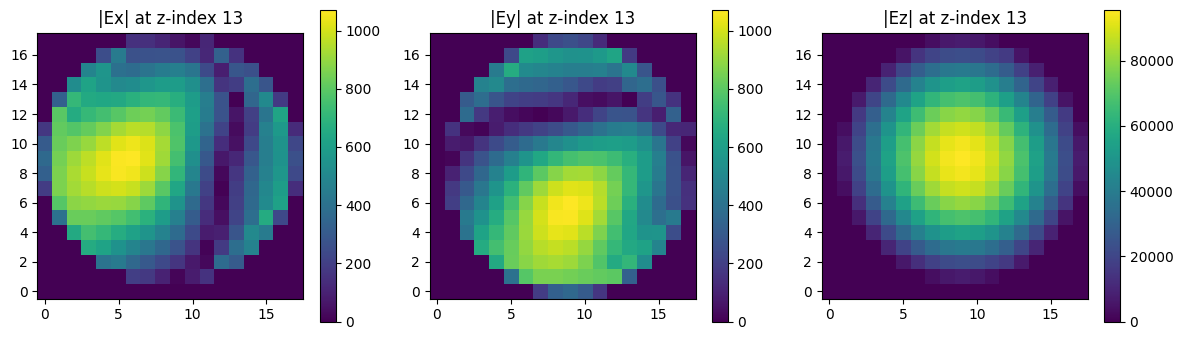

In [8]:
mode_index = int(np.argmin(abs(f_modes - target_frequency)))  # inspect / override!
f0 = float(f_modes[mode_index])
omega0 = 2 * pi * f0
e = np.asarray(modes[:, mode_index], dtype=complex)
print(f"Selected mode {mode_index}: {f0 / 1e9:.9f} GHz")

# Reconstruct component-wise E-grid voltages; reshape in FIT Fortran order.
E = np.zeros(3 * pec.N, dtype=complex)
E[pec.free_E_idx] = e
Ex, Ey, Ez = [
    E[j * pec.N : (j + 1) * pec.N].reshape((pec.Nx, pec.Ny, pec.Nz), order="F")
    for j in range(3)
]

# Midplane slice: qualitative mode-ID; sample index is a FIT mesh index.
iz = pec.Nz // 2
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, data, label in zip(axs, (Ex, Ey, Ez), ("Ex", "Ey", "Ez")):
    im = ax.imshow(np.abs(data[:, :, iz]).T, origin="lower", aspect="equal")
    ax.set_title(f"|{label}| at z-index {iz}")
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 3. Extract beam coupling $R_s/Q$ from the existing modal impedance routine

The lossless modal formula used in WAKIS is

$$Z_n(\omega)=\frac{j\omega T_n(\omega)S_n(\omega)}{C_n(\omega_n^2-\omega^2)}.$$

Near an isolated resonance, the shunt impedance convention used here satisfies

$$\frac{R_s}{Q}=\frac{|T_n(\omega_n)S_n(\omega_n)|}{\omega_n C_n}.$$

Estimate this limit from two frequencies close to the resonance, avoiding the lossless pole. This uses the same beam-current and path-integral conventions as the WAKIS modal impedance routine. **Check the CST/IDDEFIX definition of $R_s$** before interpreting absolute $R_s/Q$ agreement.

In [10]:
wake_modal = WakeSolver(
    q=Q,
    sigmaz=SIGMAZ,
    beta=BETA,
    xsource=XSOURCE,
    ysource=YSOURCE,
    xtest=XTEST,
    ytest=YTEST,
    save=False,
    verbose=0,
)

# Evaluate at very small offsets, away from the exact PEC pole.
relative_offsets = np.array([-2e-4, -1e-4, 1e-4, 2e-4])
f_probe = f0 * (1 + relative_offsets)
Z_probe, _ = pec.eigenmode_longitudinal_impedance(
    frequencies=f_probe,
    eigenfrequencies=np.array([f0]),
    eigenvectors=e[:, None],
    wake=wake_modal,
    skip_cells=SKIP_CELLS,
)
# Converting the lossless frequency factor into the conventional R_s/Q.
r_over_q_samples = (
    np.abs(np.asarray(Z_probe)) * np.abs(f0**2 - f_probe**2) / (f_probe * f0)
)
r_over_q_wakis = float(np.median(r_over_q_samples))
print("WAKIS R_s/Q [Ohm]:", r_over_q_wakis)
print("Sampling spread [%]:", 100 * np.ptp(r_over_q_samples) / r_over_q_wakis)

WAKIS R_s/Q [Ohm]: 40.85453165494053
Sampling spread [%]: 0.16507034136721926


## 4. SIBC perturbation over conductivity

For each $\sigma$, update the SIBC surface conductivity and project $\Delta K$ onto the **same PEC eigenmode**. This retains both the damping and the reactive frequency shift. No direct frequency-domain system solve is required.

To avoid repeated geometry construction, the cell below first tries to update the wall conductivity arrays on `sibc`. The current implementation stores conductivity per magnetic DOF in `sibc.sibc_sigma`; if your local code differs, use the rebuild fallback noted in the cell.

In [11]:
from scipy.sparse import diags

C_red = sibc.C_red.tocsr()
mnu_diag = sibc.Mnu.diagonal()
Cn = np.vdot(e, pec.Meps @ e).real

# Geometry and wall properties are assumed fixed, only sigma varies.
assert hasattr(sibc, "sibc_sigma"), (
    "No sibc_sigma array found; inspect _build_sibc_geometry()."
)
base_sigma = np.asarray(sibc.sibc_sigma).copy()
wall_mask = np.asarray(sibc.sibc_g) > 0
assert np.any(wall_mask)

rows_wakis = []
try:
    for sigma in sigma_values:
        # Update conductivity only on valid SIBC magnetic DOFs.
        sibc.sibc_sigma[wall_mask] = float(sigma)
        D = sibc._build_sibc_diagonal(omega0)
        # Avoid forming a new stiffness matrix: project delta operator directly.
        curl_e = C_red @ e
        delta_mnu = mnu_diag * (1 / D - 1)
        dK_projection = np.vdot(curl_e, delta_mnu * curl_e)
        domega = dK_projection / (2 * omega0 * Cn)
        if domega.imag <= 0:
            raise RuntimeError(f"Nonpositive SIBC damping at sigma={sigma:g}")
        f_res = f0 + domega.real / (2 * np.pi)
        Qn = (2 * np.pi * f_res) / (2 * domega.imag)
        rows_wakis.append(
            dict(
                sigma=float(sigma),
                f_res_hz=float(f_res),
                Q=float(Qn),
                Rs_ohm=float(r_over_q_wakis * Qn),
                R_over_Q_ohm=r_over_q_wakis,
                shift_hz=float(domega.real / (2 * np.pi)),
            )
        )
finally:
    sibc.sibc_sigma[:] = base_sigma

wakis_results = pd.DataFrame(rows_wakis)
display(wakis_results)

,sigma,f_res_hz,Q,Rs_ohm,R_over_Q_ohm,shift_hz
0,1.000000e+03,5.479934e+08,254.272042,1.038817e+04,40.854532,-1.159908e+06
1,4.216965e+03,5.485867e+08,502.513942,2.052997e+04,40.854532,-5.665620e+05
2,1.778279e+04,5.488772e+08,1012.483927,4.136456e+04,40.854532,-2.761149e+05
3,7.498942e+04,5.490188e+08,2059.832425,8.415349e+04,40.854532,-1.344852e+05
4,3.162278e+05,5.490878e+08,4210.647684,1.720240e+05,40.854532,-6.549302e+04
5,1.333521e+06,5.491214e+08,8627.430389,3.524696e+05,40.854532,-3.189334e+04
6,5.623413e+06,5.491378e+08,17697.418952,7.230198e+05,40.854532,-1.553106e+04
7,2.371374e+07,5.491457e+08,36322.874699,1.483954e+06,40.854532,-7.563127e+03
8,1.000000e+08,5.491496e+08,74570.717746,3.046552e+06,40.854532,-3.682998e+03


### Optional consistency check

We should verify that manually changing `sibc.sibc_sigma` gives the same projected loss as rebuilding a new SIBC solver at one conductivity. This is useful after changes to the SIBC implementation.

In [12]:
sigma_check = float(sigma_values[len(sigma_values) // 2])
sibc_check = make_solver("sibc", sigma=sigma_check)
assert np.array_equal(sibc.free_E_idx, sibc_check.free_E_idx)
assert np.allclose(sibc.sibc_g, sibc_check.sibc_g)
assert np.allclose(sibc.Mnu.diagonal(), sibc_check.Mnu.diagonal())
sibc.sibc_sigma[wall_mask] = sigma_check
try:
    np.testing.assert_allclose(
        sibc._build_sibc_diagonal(omega0),
        sibc_check._build_sibc_diagonal(omega0),
        rtol=1e-10,
        atol=1e-10,
    )
    print("SIBC conductivity update matches rebuilt solver.")
finally:
    sibc.sibc_sigma[:] = base_sigma

Generating grid with 8424 mesh cells...


D:\Wakis\WAKIS\wakis\gridFIT3D.py:4428: UserWarning: Conformal geometry diagnostics:
1096 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
48 edges contain multiple crossing positions. 0 of these are currently used by the conformal discretization; one representative crossing is selected on each edge.
48 edges cross the same STL at more than one distinct position. The geometry on these edges is not fully resolved by the current single-crossing treatment.
  dual z-edge (3, 7, 7): shell
  dual z-edge (3, 7, 17): shell
  dual z-edge (3, 8, 7): shell
  dual z-edge (3, 8, 17): shell
  dual z-edge (3, 9, 7): shell
  ... and 43 more.
  self._warn_interface_diagnostics()


Initializing Electromagnetic solver...
SIBC conductivity update matches rebuilt solver.


## 5. CST file discovery and conductivity mapping

Place CST impedance files in a folder beside this notebook, or set `cst_dir` below. **The file header is authoritative:** `sigma_sibc=...` is interpreted as wall conductivity in S/m, while `sigma=...` in the header may denote bunch length and must **not** be used as wall conductivity.

Only `*.txt` files containing `sigma_sibc` metadata (or manually listed in `cst_file_sigma`) are loaded. Files without a matching conductivity are reported, not silently guessed.

In [ ]:
cst_dir = Path.cwd()  # adjust if CST exports live in a subfolder
cst_file_sigma = {}  # optional mapping, e.g. {"my_export.txt": 1e6}


def read_cst_file(path):
    with open(path, encoding="utf-8-sig", errors="replace") as fh:
        header = "".join(fh.readline() for _ in range(5))
    match = re.search(r"\bsigma_sibc\s*=\s*([+\-\d.eE]+)", header, re.I)
    sigma = float(match.group(1)) if match else cst_file_sigma.get(path.name)
    if sigma is None:
        raise ValueError("No sigma_sibc in header and no manual mapping")
    arr = np.loadtxt(path, comments="#", usecols=(0, 1, 2))
    arr = np.atleast_2d(arr)
    frequencies = arr[:, 0]
    impedance = arr[:, 1] + 1j * arr[:, 2]
    mask = np.isfinite(frequencies) & np.isfinite(impedance) & (frequencies > 0)
    frequencies, impedance = frequencies[mask], impedance[mask]
    order = np.argsort(frequencies)
    return sigma, frequencies[order], impedance[order]


cst_records = []
for path in sorted(cst_dir.glob("*.txt")):
    try:
        sigma, frequencies_cst, impedance_cst = read_cst_file(path)
    except (ValueError, OSError) as err:
        print(f"Skipping {path.name}: {err}")
        continue
    cst_records.append((path, sigma, frequencies_cst, impedance_cst))

print(f"Found {len(cst_records)} CST impedance files")
for path, sigma, f, Z in cst_records:
    print(f"{path.name}: sigma={sigma:g} S/m; {len(f)} frequency samples")

## 6. IDDEFIX: fit one CST resonance per conductivity

We fit a classical **longitudinal resonator** close to the selected WAKIS mode. The fit is constrained to a frequency interval around the *WAKIS SIBC-corrected resonance* at each conductivity. Use the same shunt-impedance definition in CST and WAKIS.

**Caution:** Insufficient CST wake length broadens sharp resonances. Check `points_per_fwhm` and the complex relative fitting error before trusting a fitted $Q$.

The code uses the `EvolutionaryAlgorithm` API already present in your original notebook.

In [ ]:
cst_results_rows = []
cst_fits = {}
fit_half_window_hz = 60e6
maxiter = 400
popsize = 12

for path, sigma, f_all, Z_all in cst_records:
    i_near = int(np.argmin(abs(np.log(wakis_results.sigma.values / sigma))))
    row = wakis_results.iloc[i_near]
    if not np.isclose(row.sigma, sigma, rtol=5e-3):
        print(f"Skipping {path.name}: sigma={sigma:g} not in WAKIS sweep")
        continue

    f_center = row.f_res_hz
    sel = (f_all >= f_center - fit_half_window_hz) & (
        f_all <= f_center + fit_half_window_hz
    )
    f_fit, Z_fit = f_all[sel], Z_all[sel]
    if len(f_fit) < 8:
        print(f"Skipping {path.name}: only {len(f_fit)} samples near resonance")
        continue
    delta_f = float(np.median(np.diff(f_fit)))

    # Choose generous physically positive bounds; tighten as needed for problematic spectra.
    f_bounds = (max(f_fit.min(), f_center - 20e6), min(f_fit.max(), f_center + 20e6))
    q_guess = float(row.Q)
    q_bounds = (max(1.0, q_guess / 20), max(50.0, q_guess * 20))
    r_guess = float(row.Rs_ohm)
    rs_bounds = (max(1e-8, r_guess / 100), max(100.0, r_guess * 100))
    bounds = [rs_bounds, q_bounds, f_bounds]

    model = iddefix.EvolutionaryAlgorithm(
        f_fit,
        Z_fit,
        N_resonators=1,
        parameterBounds=bounds,
        plane="longitudinal",
        objectiveFunction=iddefix.ObjectiveFunctions.sumOfSquaredError,
    )
    model.run_differential_evolution(maxiter=maxiter, popsize=popsize, tol=1e-6)
    model.run_minimization_algorithm()
    Rs, Q_cst, f_res_cst = np.asarray(model.minimizationParameters, dtype=float)[:3]
    Z_model = np.asarray(model.get_impedance())
    err = np.linalg.norm(Z_model - Z_fit) / max(np.linalg.norm(Z_fit), 1e-30)
    ppw = f_res_cst / Q_cst / delta_f
    cst_results_rows.append(
        dict(
            sigma=float(sigma),
            f_res_hz=float(f_res_cst),
            Q=float(Q_cst),
            Rs_ohm=float(Rs),
            R_over_Q_ohm=float(Rs / Q_cst),
            fit_error=float(err),
            points_per_fwhm=float(ppw),
            filename=path.name,
        )
    )
    cst_fits[sigma] = (f_fit, Z_fit, Z_model)
    print(
        f"{path.name}: f={f_res_cst / 1e6:.3f} MHz, Q={Q_cst:.1f}, "
        f"Rs={Rs:.3g} Ohm, relative error={err:.3g}, points/FWHM={ppw:.2f}"
    )

cst_results = pd.DataFrame(cst_results_rows)
if len(cst_results):
    display(cst_results)
else:
    print("No matching CST spectra fitted. Add CST files and rerun this cell.")

## 7. Conductivity comparison

The plots show WAKIS and CST results side by side. $Q$ and $R_s$ typically scale approximately as $\sqrt{\sigma}$ for weak wall losses, while $R_s/Q$ is approximately constant. The resonance shift verifies the reactive part of SIBC.

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
metrics = [
    ("Q", "Quality factor Q", True),
    ("f_res_hz", "Resonance frequency [MHz]", False),
    ("Rs_ohm", "Shunt impedance Rs [Ohm]", True),
    ("R_over_Q_ohm", "Rs / Q [Ohm]", False),
]
for ax, (key, label, log_y) in zip(axs.flat, metrics):
    scale = 1e-6 if key == "f_res_hz" else 1
    ax.plot(wakis_results.sigma, wakis_results[key] * scale, "o-", label="WAKIS SIBC")
    if len(cst_results):
        cs = cst_results.sort_values("sigma")
        ax.plot(cs.sigma, cs[key] * scale, "s--", label="CST + IDDEFIX")
    ax.set_xscale("log")
    if log_y:
        ax.set_yscale("log")
    ax.set_xlabel("Conductivity [S/m]")
    ax.set_ylabel(label)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, ylabel in [
    (axs[0], "Q", "Q / sqrt(sigma)"),
    (axs[1], "f_res_hz", "f_res - f_PEC [kHz]"),
]:
    for df, label, marker in [
        (wakis_results, "WAKIS SIBC", "o-"),
        (cst_results, "CST + IDDEFIX", "s--"),
    ]:
        if df.empty:
            continue
        df = df.sort_values("sigma")
        y = df.Q / np.sqrt(df.sigma) if key == "Q" else (df.f_res_hz - f0) / 1e3
        ax.plot(df.sigma, y, marker, label=label)
    ax.set_xscale("log")
    ax.set_xlabel("Conductivity [S/m]")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Optional: inspect individual CST fits and save results

Reject fitted $Q$ values when frequency resolution / wake length or fitting residual make them unreliable. Some spectra may contain additional modes or an impedance baseline that a single-resonator IDDEFIX model cannot represent.

In [ ]:
for sigma, (f, measured, fitted) in cst_fits.items():
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
    for axis, part, title in [(ax[0], np.real, "Re(Z)"), (ax[1], np.imag, "Im(Z)")]:
        axis.plot(f / 1e6, part(measured), ".", label="CST")
        axis.plot(f / 1e6, part(fitted), "-", label="IDDEFIX")
        axis.set_title(title)
        axis.set_xlabel("Frequency [MHz]")
        axis.grid(True, alpha=0.3)
        axis.legend()
    fig.suptitle(f"sigma = {sigma:.3g} S/m")
    plt.tight_layout()
    plt.show()

wakis_results.to_csv("pillbox_wakis_sibc_conductivity_sweep.csv", index=False)
if len(cst_results):
    cst_results.to_csv("pillbox_cst_iddefix_conductivity_sweep.csv", index=False)

## Interpretation and practical notes

1. **First verify mode identity and boundary conditions.** CST and WAKIS must use the same geometry, PEC terminations, conductivity, source/test trajectories and shunt-impedance convention.
2. **The WAKIS PEC modal coupling $R_s/Q$ is held fixed** over the sweep, consistent with first-order perturbation theory.
3. **The WAKIS surface model assumes a good conductor and a thick wall**. For low conductivities, compare skin depth with physical wall thickness; surface-impedance and first-order perturbation approximations may fail.
4. **CST wakefield data contain finite-wake effects.** High-$Q$ resonances may be poorly resolved even if the fitted model converges.
5. **No direct FD sweep** is performed by this notebook.